In [3]:
%pip -q install "statsmodels>=0.14,<0.16" "pandas>=2.0" "scipy>=1.10" "matplotlib>=3.7" "requests>=2.28"

Note: you may need to restart the kernel to use updated packages.


In [1]:
import io
import warnings
from pathlib import Path

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import requests
import statsmodels
from scipy import stats
from statsmodels.graphics.tsaplots import plot_acf, plot_pacf
from statsmodels.tsa.stattools import adfuller, kpss, acf, pacf
from statsmodels.tsa.arima.model import ARIMA
from statsmodels.stats.diagnostic import acorr_ljungbox

pd.set_option("display.max_columns", 30)
plt.rcParams["figure.figsize"] = (11, 4)
SEED = 2026
rng = np.random.default_rng(SEED)
print("pandas:", pd.__version__, "| statsmodels:", statsmodels.__version__)

pandas: 3.1.1 | statsmodels: 0.15.0


In [2]:
FRED_CSV = "https://fred.stlouisfed.org/graph/fredgraph.csv?id=VIXCLS"
LOCAL_CSV = Path("VIXCLS_source_FRED.csv")
END_DATE = "2026-09-30"

def lire_vix_csv(path):
    raw = pd.read_csv(path, encoding="utf-8-sig")
    raw.columns = raw.columns.str.strip()

    # Compatibilité avec les différents exports FRED.
    if "observation_date" in raw.columns:
        raw = raw.rename(columns={"observation_date": "DATE"})

    if not {"DATE", "VIXCLS"}.issubset(raw.columns):
        raise ValueError(
            f"Colonnes inattendues : {list(raw.columns)}"
        )

    raw["DATE"] = pd.to_datetime(raw["DATE"], errors="raise")
    raw["VIXCLS"] = pd.to_numeric(
        raw["VIXCLS"], errors="coerce"
    )

    raw = (
        raw.sort_values("DATE")
           .drop_duplicates("DATE")
           .loc[lambda x: x["DATE"] <= END_DATE]
           .set_index("DATE")
    )

    vix = raw["VIXCLS"].dropna().astype(float)
    vix.name = "VIX"

    assert not vix.empty
    assert vix.index.is_unique
    assert vix.index.is_monotonic_increasing
    assert np.isfinite(vix.to_numpy()).all()
    assert (vix > 0).all()

    return vix


try:
    if not LOCAL_CSV.exists():
        raise FileNotFoundError("CSV absent")

    vix = lire_vix_csv(LOCAL_CSV)
    print("Fichier local validé.")

except (FileNotFoundError, ValueError, pd.errors.ParserError):
    print("Téléchargement du CSV officiel FRED...")

    response = requests.get(FRED_CSV, timeout=40)
    response.raise_for_status()
    LOCAL_CSV.write_bytes(response.content)

    vix = lire_vix_csv(LOCAL_CSV)
    print("Téléchargement et validation effectués.")

print("Nombre d'observations :", len(vix))
print("Première date :", vix.index.min())
print("Dernière date :", vix.index.max())

display(vix.head().to_frame())
display(vix.tail().to_frame())


Téléchargement du CSV officiel FRED...
Téléchargement et validation effectués.
Nombre d'observations : 9285
Première date : 1990-01-02 00:00:00
Dernière date : 2026-09-30 00:00:00


,VIX
DATE,
1990-01-02,17.24
1990-01-03,18.19
1990-01-04,19.22
1990-01-05,20.11
1990-01-08,20.26


,VIX
DATE,
2026-09-24,15.67
2026-09-25,14.87
2026-09-28,16.07
2026-09-29,16.04
2026-09-30,16.34


1.1 Audit des données
1) La volatilité implicite est une mesure ex ante issue du prix des options sur le S&P 500 qui reflète l'anticipation du marché sur 30 jours. La volatilité réalisée est une mesure ex post calculée comme l'écart-type des rendements passés sur une période donnée.
2) Les marchés financiers ne cotent pas les week-ends ni jours fériés, ce qui fausserait la dynamique autorégressive du processus.
3)C'est une hausse de 10 points d'indice et non un rendement financier de 10 % car le VIX mesure une volatilité annualisée.

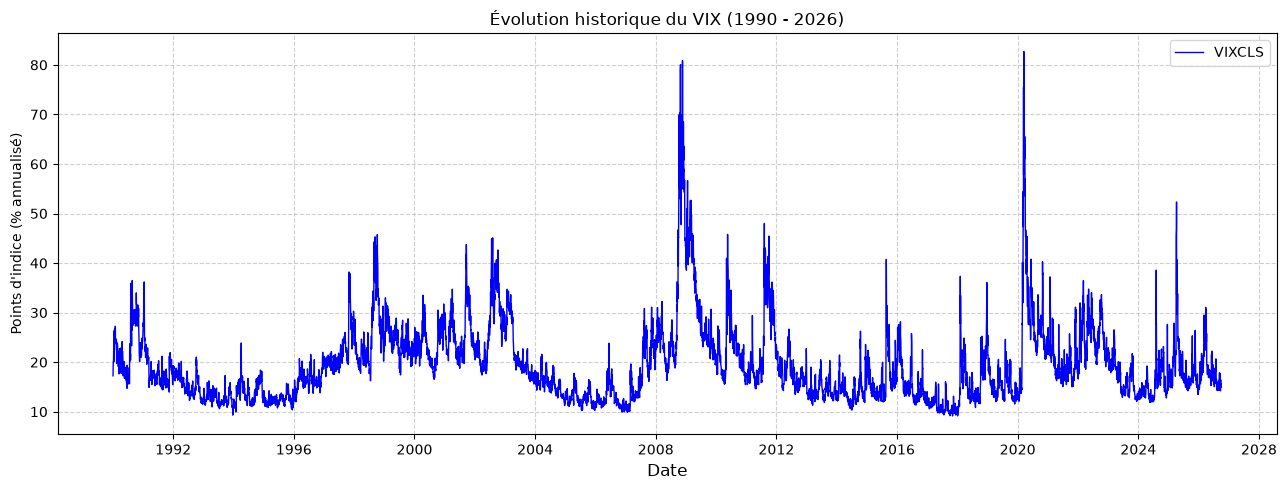

Statistiques Descriptives du VIX


,VIX
count,9285.000000
mean,19.423943
std,7.715886
min,9.140000
25%,13.990000
50%,17.570000
75%,22.680000
max,82.690000


In [3]:
# Visualisation et statistiques descriptives de la série du VIX
fig, ax = plt.subplots(figsize=(13, 5))
ax.plot(vix.index, vix.values, color="blue", linewidth=1, label='VIXCLS')
ax.set_title("Évolution historique du VIX (1990 - 2026)")
ax.set_xlabel("Date", fontsize=12)
ax.set_ylabel("Points d'indice (% annualisé)")
ax.grid(True, linestyle='--', alpha=0.6)
ax.legend(loc='upper right')
plt.tight_layout()
plt.show()

print("Statistiques Descriptives du VIX")
display(vix.describe().to_frame())

2]Exploration, lissage et transformations

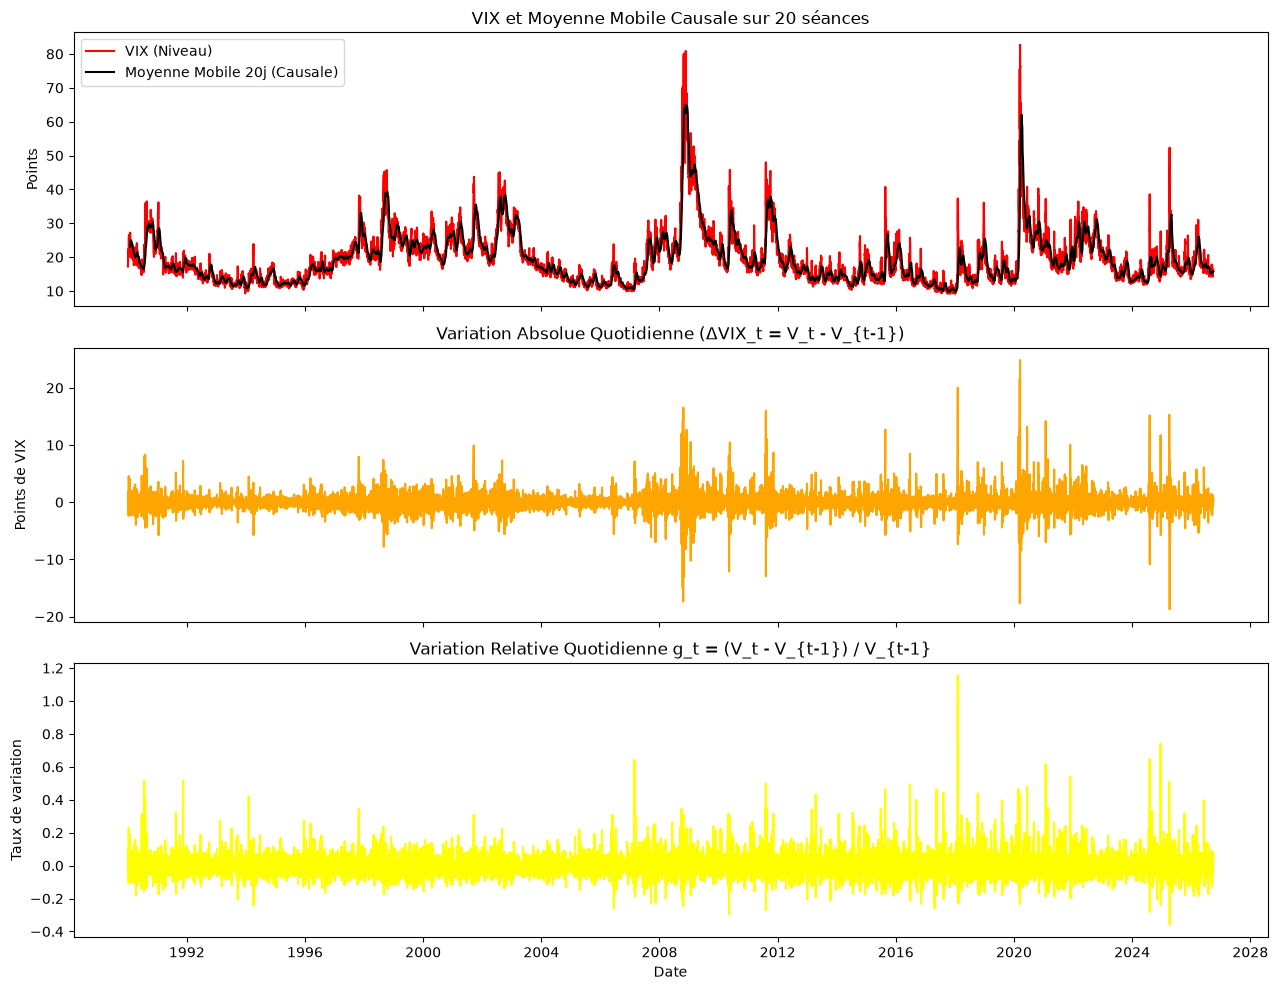

In [9]:
# Calcul des variations et lissage
delta_vix = vix.diff().dropna()
relative_vix = vix.pct_change().dropna()
rolling_mean_20 = vix.rolling(window=20).mean()

fig, axes = plt.subplots(3, 1,figsize=(13, 10), sharex=True)

#Niveau et Moyenne Mobile 20 jours
axes[0].plot(vix.index, vix, label='VIX (Niveau)', color="red")
axes[0].plot(rolling_mean_20.index, rolling_mean_20, label='Moyenne Mobile 20j (Causale)', color="black")
axes[0].set_title("VIX et Moyenne Mobile Causale sur 20 séances")
axes[0].set_ylabel("Points")
axes[0].legend()

#Variation absolue (ΔVIX)
axes[1].plot(delta_vix.index, delta_vix, color="orange")
axes[1].set_title("Variation Absolue Quotidienne (ΔVIX_t = V_t - V_{t-1})")
axes[1].set_ylabel("Points de VIX")

#Variation relative (g_t)
axes[2].plot(relative_vix.index, relative_vix, color="yellow")
axes[2].set_title("Variation Relative Quotidienne g_t = (V_t - V_{t-1}) / V_{t-1}")
axes[2].set_ylabel("Taux de variation")
axes[2].set_xlabel("Date")

plt.tight_layout()
plt.show()